# Step 1 (Question 4): Is the Flying Drones Sector Patent-Heavy or Secrecy-Reliant?

**Team 28 · Flying Drones · Client: Leonardo S.p.A.**  
**Course:** Innovation Management (`01TXIWS`, A.Y. 2026/27 · Politecnico di Torino · Prof. Grazia Sveva Ascione)

### Analytical Framework (Appropriability & Indirect Signals of Secrecy)
Because trade secrets and state-classified military inventions (e.g., under national Invention Secrecy Acts) are **unobservable** in PATSTAT, we evaluate patent propensity vs. secrecy using **five converging empirical tests**, grounded in Cohen, Nelson & Walsh (2000), Arundel (2001), Teece (1986), and Acosta et al. (2018):

1. **Internal UAV Split:** Compare **Military/Warfare**, **Dual-Use (Surveillance/ISR)**, and **Civil/Commercial** UAV families (share of patent volume vs. defense's true share of global UAV spending).
2. **External Benchmarks:** Compare Flying Drones against **Manned Aircraft** (`B64C`, `B64D`, excl. UAVs) and **Autonomous Road Vehicles** (`B60W 60/`, excl. UAVs).
3. **International Breadth & Secrecy-Order Signature:** Mean family size, PCT share, ≥2 IP5 office share, and **single-office-only share** (national secrecy orders & ITAR/export controls restrict foreign filings).
4. **Applicant Sector Mix:** Share of `COMPANY`, `UNIVERSITY`, `GOV NON-PROFIT`, and `INDIVIDUAL` filers across segments.
5. **Defence Primes (incl. Leonardo) vs. Commercial UAV Leaders (DJI, Autel, Parrot, EHang, XAG, Skydio)** using our harmonized corporate-tree engine (`src/harmonize.py`).


## 1. Setup & Shared Locked Step 0 Family Universe


In [1]:
import sys
from pathlib import Path

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / "src").exists() and (REPO_ROOT.parent / "src").exists():
    REPO_ROOT = REPO_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import PercentFormatter
from sqlalchemy import and_, case, distinct, func, or_

from epo.tipdata.patstat import PatstatClient
from epo.tipdata.patstat.database.models import (
    TLS201_APPLN,
    TLS202_APPLN_TITLE,
    TLS206_PERSON,
    TLS207_PERS_APPLN,
    TLS224_APPLN_CPC,
)

from src.config_loader import get_last_complete_year, load_config
from src.harmonize import harmonize_applicant_names
from src.step0_loader import get_step0_families, iter_batches
from src.step1_metrics import (
    build_q4_interpretation_paragraph,
    classify_uav_use_segment,
    compute_post_peak_decomposition,
    summarize_patenting_intensity,
)

ENV = "PROD"                      # Switch to "PROD" for final deck numbers
STEP0_CSV_PATH = None             # Uses the EXACT same locked Step 0 CSV as Notebook 01
INCLUDE_BOUNDARY_RESCUE = True
BATCH_SIZE = 5000

cfg = load_config(REPO_ROOT / "config" / "sector.yaml")
YEAR_MIN = int(cfg["time_window"]["year_min"])
YEAR_MAX = int(cfg["time_window"]["year_max"])
LAST_COMPLETE_YEAR = get_last_complete_year(cfg)
IPR_TYPE = cfg["counting_rules"]["ipr_type"]
IP5_OFFICES = tuple(cfg["counting_rules"]["ip5_offices"])

Q4_CFG = cfg["q4_secrecy"]
OUTPUT_DIR = REPO_ROOT / "outputs" / "q4_secrecy"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 140,
    "savefig.dpi": 300,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
})

patstat = PatstatClient(env=ENV)
db = patstat.orm()

step0_df, step0_source = get_step0_families(
    patstat=patstat,
    db=db,
    cfg=cfg,
    override_csv_path=STEP0_CSV_PATH,
    include_boundary_rescue=INCLUDE_BOUNDARY_RESCUE,
)
uav_fids = step0_df["docdb_family_id"].astype(int).tolist()
uav_fid_set = set(uav_fids)

print(f"Environment : {ENV} | Step 0 source: {step0_source}")
print(f"Locked UAV families loaded: {len(uav_fids):,} (complete window {YEAR_MIN}–{LAST_COMPLETE_YEAR})")


Environment : PROD | Step 0 source: locked_csv:../data/raw/00_family_roster.csv
Locked UAV families loaded: 71,197 (complete window 2004–2022)


## 2. Segment UAVs (Military / Dual-Use / Civil) & Verify Military Precision


In [2]:
def fetch_batched(query_builder, family_ids, batch_size=BATCH_SIZE):
    frames = []
    for batch in iter_batches(family_ids, batch_size=batch_size):
        chunk = patstat.df(query_builder(batch))
        if chunk is not None and not chunk.empty:
            frames.append(chunk)
    return pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()


# Fetch CPC codes for all locked UAV families
uav_cpc = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id,
        TLS224_APPLN_CPC.cpc_class_symbol,
    )
    .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    )
    .distinct(),
    uav_fids,
)

seg_df = classify_uav_use_segment(
    family_cpc_df=uav_cpc,
    all_uav_family_ids=uav_fids,
    military_prefixes=Q4_CFG["military_cpc_prefixes"],
    dual_use_prefixes=Q4_CFG["dual_use_cpc_prefixes"],
)
display(seg_df["segment"].value_counts().rename("families").to_frame())

# Military precision sanity check: inspect 20 random English titles of military-tagged UAV families
mil_fids = seg_df.loc[seg_df["segment"] == "military", "docdb_family_id"].tolist()
if mil_fids:
    sample_ids = pd.Series(mil_fids).sample(n=min(20, len(mil_fids)), random_state=42).tolist()
    mil_sample = patstat.df(
        db.query(
            TLS201_APPLN.docdb_family_id,
            func.min(TLS202_APPLN_TITLE.appln_title).label("title"),
        )
        .join(TLS202_APPLN_TITLE, TLS201_APPLN.appln_id == TLS202_APPLN_TITLE.appln_id)
        .filter(
            TLS201_APPLN.docdb_family_id.in_(sample_ids),
            TLS202_APPLN_TITLE.appln_title_lg == "en",
        )
        .group_by(TLS201_APPLN.docdb_family_id)
    )
    mil_sample.to_csv(OUTPUT_DIR / "military_precision_sample.csv", index=False)
    print("Sample of military-classified UAV families (verify manually for Technical Appendix):")
    display(mil_sample.head(15))


,families
segment,
civil_and_other,67853
dual_use,1714
military,1630


Sample of military-classified UAV families (verify manually for Technical Appendix):


,docdb_family_id,title
0,99484175,Firefighting drone that automatically moves to...
1,92565641,Launching device and launching method for vehi...
2,99990020,Smart drone forming device and method for gene...
3,61944796,Anti-unmanned-aerial-vehicle catching device w...
4,58669461,CERAMIC-ENCAPSULATED THERMOPOLYMER PATTERN OR ...
5,63295162,Anti-aircraft autonomous undersea system (AUS)...
6,60120112,PORTABLE CLOSE AIR SUPPORT SYSTEM AND PAYLOAD ...
7,99510926,Explosive Information Visualization System and...
8,92447595,Water-air amphibious aircraft and use method t...
9,87883159,MULTISPECTRAL STEP-AND-STARE IMAGING WITH SING...


## 3. Benchmarks & Family Patenting Intensity Profiles


,families,mean_family_size,median_family_size,mean_offices,pct_share_pct,multi_ip5_share_pct,single_office_share_pct,grant_rate_pct
group,,,,,,,,
All flying drones,50782,1.85,1.0,1.42,20.45,16.14,81.86,59.84
Military drones,1122,2.36,1.0,1.69,30.93,21.93,71.75,70.05
Dual-use (ISR/surveillance) drones,1046,2.34,1.0,1.63,27.72,22.66,73.23,66.54
Civil & commercial drones,48614,1.82,1.0,1.41,20.05,15.86,82.28,59.46
Manned aircraft (excl. UAVs),66608,2.47,1.0,2.09,20.67,36.04,57.68,72.95
Autonomous road vehicles,18829,2.74,2.0,2.20,26.40,49.67,47.91,73.31


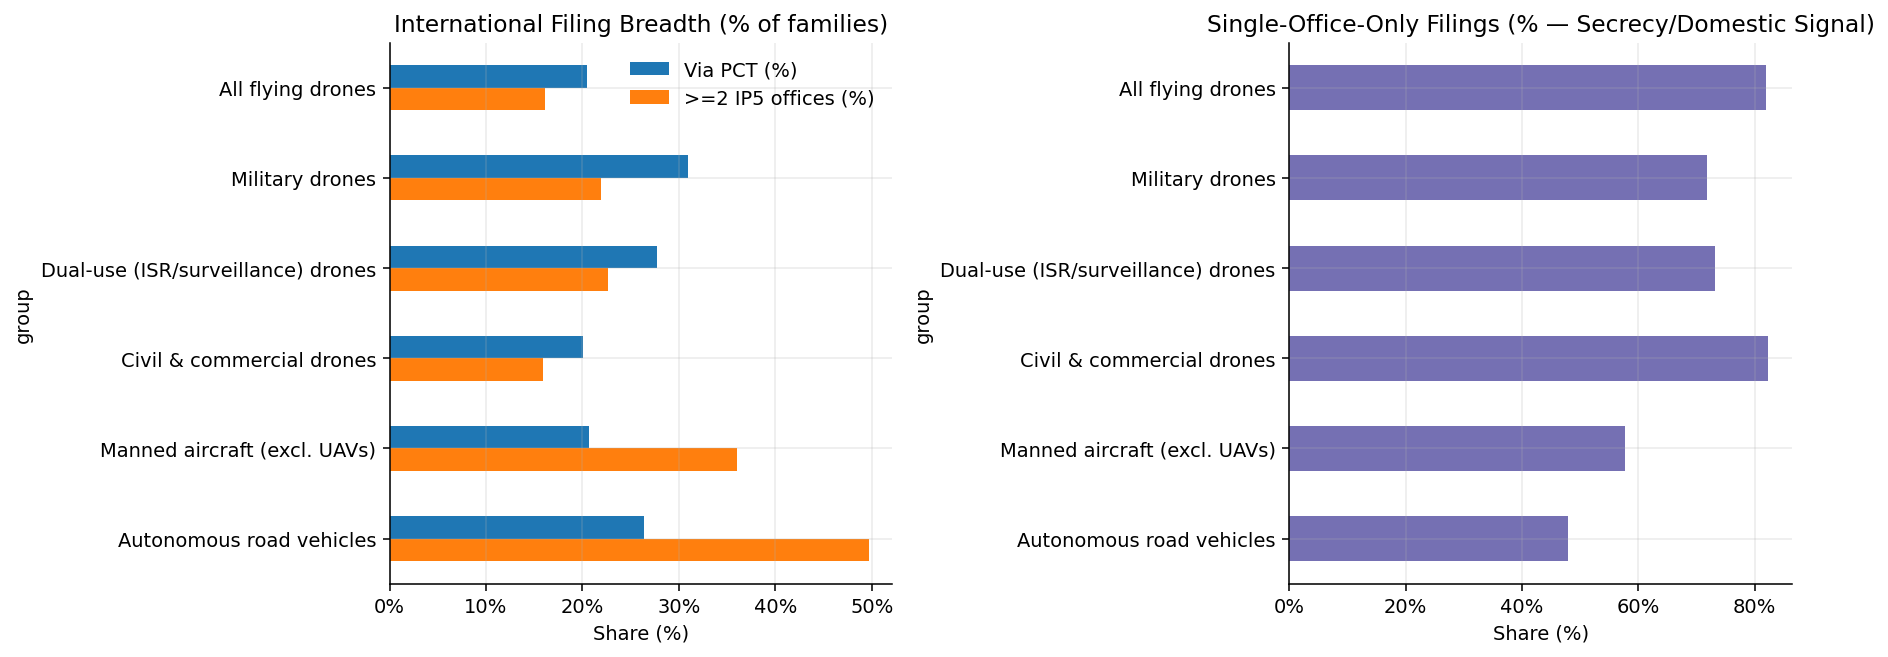

In [3]:
IS_PCT_APPLN = and_(TLS201_APPLN.appln_auth == "WO", TLS201_APPLN.appln_kind.like("W%"))


def _prefix_cond(col, prefixes):
    clean = func.replace(col, " ", "")
    return or_(*(clean.like(p.replace(" ", "") + "%") for p in prefixes))


def fetch_profiles_for_fids(family_ids, group_name):
    df = fetch_batched(
        lambda batch: db.query(
            TLS201_APPLN.docdb_family_id.label("fid"),
            func.min(TLS201_APPLN.earliest_filing_year).label("year"),
            func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
            func.count(distinct(case((TLS201_APPLN.appln_auth != "WO", TLS201_APPLN.appln_auth)))).label("n_offices"),
            func.count(distinct(case((TLS201_APPLN.appln_auth.in_(list(IP5_OFFICES)), TLS201_APPLN.appln_auth)))).label("n_ip5"),
            func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
            func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        )
        .filter(
            TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(batch),
        )
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(func.min(TLS201_APPLN.earliest_filing_year).between(YEAR_MIN, LAST_COMPLETE_YEAR)),
        family_ids,
    )
    return df.assign(group=group_name)


def fetch_benchmark_profiles(cpc_prefixes, group_name):
    # Compute benchmark profiles directly inside PATSTAT SQL (much faster on PROD), then drop any UAV families in pandas
    q_ids = (
        db.query(TLS201_APPLN.docdb_family_id.label("docdb_family_id"))
        .join(TLS224_APPLN_CPC, TLS201_APPLN.appln_id == TLS224_APPLN_CPC.appln_id)
        .filter(
            TLS201_APPLN.ipr_type == IPR_TYPE,
            _prefix_cond(TLS224_APPLN_CPC.cpc_class_symbol, cpc_prefixes),
        )
        .distinct()
        .subquery()
    )
    q_prof = (
        db.query(
            TLS201_APPLN.docdb_family_id.label("fid"),
            func.min(TLS201_APPLN.earliest_filing_year).label("year"),
            func.max(TLS201_APPLN.docdb_family_size).label("family_size"),
            func.count(distinct(case((TLS201_APPLN.appln_auth != "WO", TLS201_APPLN.appln_auth)))).label("n_offices"),
            func.count(distinct(case((TLS201_APPLN.appln_auth.in_(list(IP5_OFFICES)), TLS201_APPLN.appln_auth)))).label("n_ip5"),
            func.max(case((IS_PCT_APPLN, 1), else_=0)).label("is_pct"),
            func.max(case((TLS201_APPLN.granted == "Y", 1), else_=0)).label("is_granted"),
        )
        .filter(
            TLS201_APPLN.ipr_type == IPR_TYPE,
            TLS201_APPLN.docdb_family_id.in_(db.query(q_ids.c.docdb_family_id)),
        )
        .group_by(TLS201_APPLN.docdb_family_id)
        .having(func.min(TLS201_APPLN.earliest_filing_year).between(YEAR_MIN, LAST_COMPLETE_YEAR))
    )
    df = patstat.df(q_prof)
    df = df[~df["fid"].isin(uav_fid_set)].copy()
    return df.assign(group=group_name)


uav_all_prof = fetch_profiles_for_fids(uav_fids, "All flying drones")
uav_seg_prof = uav_all_prof.merge(seg_df, left_on="fid", right_on="docdb_family_id", how="inner")

seg_label_map = {
    "military": "Military drones",
    "dual_use": "Dual-use (ISR/surveillance) drones",
    "civil_and_other": "Civil & commercial drones",
}
profile_frames = [uav_all_prof]
for seg_key, seg_label in seg_label_map.items():
    sub = uav_seg_prof[uav_seg_prof["segment"] == seg_key].drop(columns=["docdb_family_id", "segment"]).copy()
    sub["group"] = seg_label
    profile_frames.append(sub)

for b_key, b_cfg in Q4_CFG["benchmarks"].items():
    profile_frames.append(fetch_benchmark_profiles(b_cfg["cpc_prefixes"], b_cfg["label"]))

all_profiles = pd.concat(profile_frames, ignore_index=True)
intensity_table = summarize_patenting_intensity(all_profiles)
intensity_table.to_csv(OUTPUT_DIR / "q4_patenting_intensity.csv")
display(intensity_table.round(2))

# Figure 1: International breadth & single-office signature across UAV segments vs benchmarks
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_df = intensity_table[["pct_share_pct", "multi_ip5_share_pct", "single_office_share_pct"]]
plot_df[["pct_share_pct", "multi_ip5_share_pct"]].plot(kind="barh", ax=axes[0])
axes[0].set(title="International Filing Breadth (% of families)", xlabel="Share (%)")
axes[0].xaxis.set_major_formatter(PercentFormatter(100))
axes[0].invert_yaxis()
axes[0].legend(["Via PCT (%)", ">=2 IP5 offices (%)"], frameon=False)

intensity_table["single_office_share_pct"].plot(kind="barh", ax=axes[1], color="#7570b3")
axes[1].set(title="Single-Office-Only Filings (% — Secrecy/Domestic Signal)", xlabel="Share (%)")
axes[1].xaxis.set_major_formatter(PercentFormatter(100))
axes[1].invert_yaxis()
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig01_q4_patenting_intensity.png", bbox_inches="tight")
plt.show()


## 4. Defence Primes (incl. Leonardo) vs. Commercial UAV Leaders (Harmonized)


,role,country,families,military_families,dual_use_families,civil_families,matched_psn_variants
company,,,,,,,
DJI,Commercial UAV leader,CN,1631,9,20,1602,37
STATE GRID CORP OF CHINA,State utility (inspection UAVs),CN,724,0,1,723,400
BOEING,Defence prime,US,571,29,30,512,22
AUTEL ROBOTICS,Commercial UAV leader,CN,424,0,5,419,17
BEIHANG UNIVERSITY,University,CN,362,3,0,359,7
NANJING UNIV AERONAUTICS ASTRONAUTICS,University,CN,314,4,1,309,1
NORTHWESTERN POLYTECHNICAL UNIVERSITY,University,CN,293,3,0,290,5
ALPHABET,"Tech group (Google, X Development, Wing, Makani)",US,278,2,4,272,9
TEXTRON,Defence / aerospace group (Bell),US,256,16,7,233,15


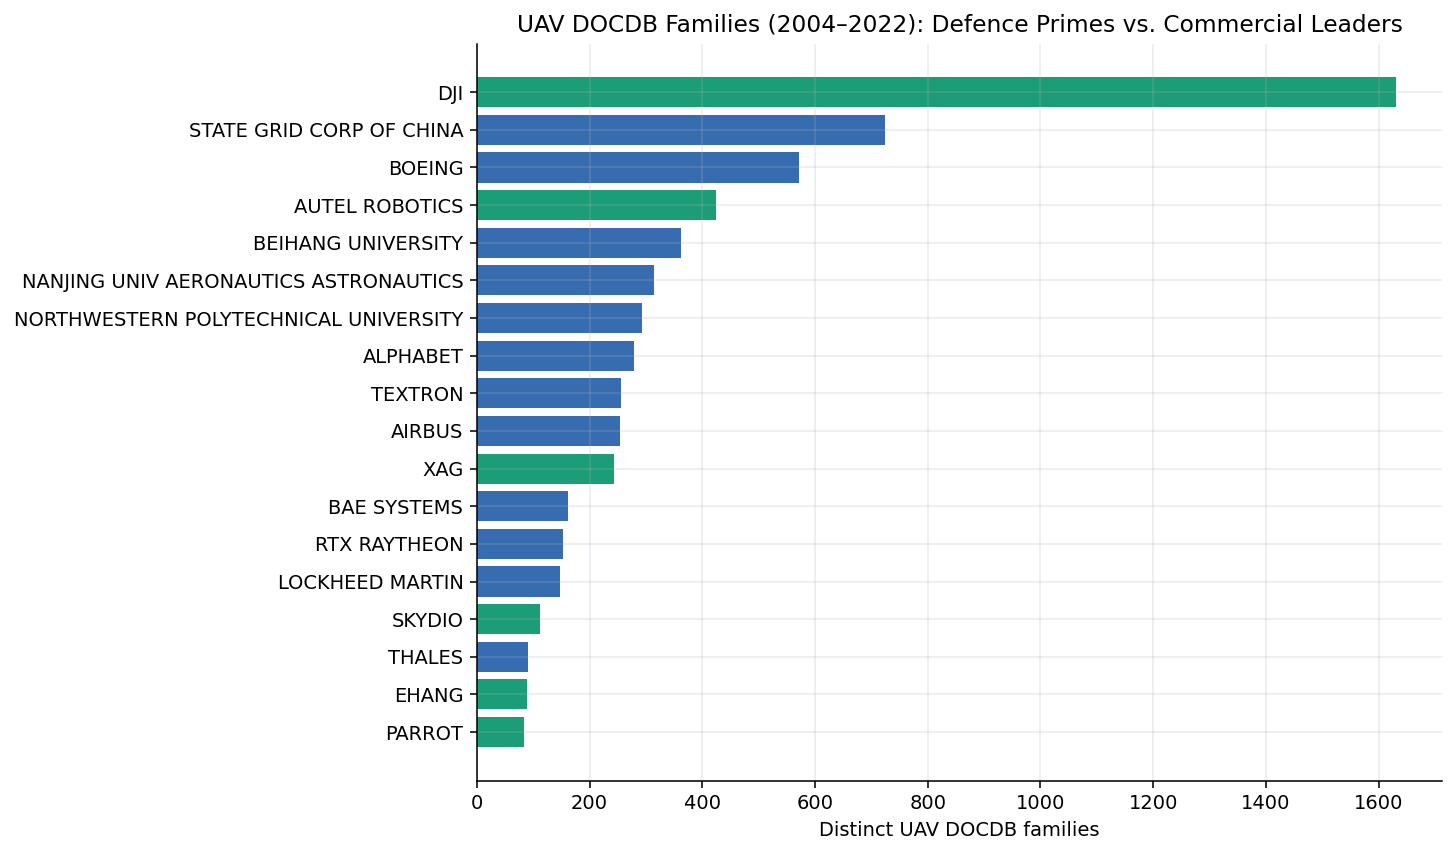

In [4]:
# Fetch applicants for complete-window UAV families & harmonize with UAV corporate tree
uav_complete_fids = uav_all_prof["fid"].astype(int).tolist()
uav_applts = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id.label("fid"),
        TLS206_PERSON.psn_name,
        TLS206_PERSON.psn_sector,
        func.trim(TLS206_PERSON.person_ctry_code).label("ctry"),
    )
    .join(TLS207_PERS_APPLN, TLS201_APPLN.appln_id == TLS207_PERS_APPLN.appln_id)
    .join(TLS206_PERSON, TLS207_PERS_APPLN.person_id == TLS206_PERSON.person_id)
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS207_PERS_APPLN.applt_seq_nr > 0,
        TLS201_APPLN.docdb_family_id.in_(batch),
    )
    .distinct(),
    uav_complete_fids,
)

# Harmonize with corporate-tree mapping (e.g. FINMECCANICA/SELEX/ALENIA -> LEONARDO; DA JIANG -> DJI)
name_map = harmonize_applicant_names(
    uav_applts["psn_name"].dropna().unique(),
    domain_groups=cfg["domain_corporate_groups"],
    apply_domain_aliases=True,
)
uav_applts["canon_applicant"] = uav_applts["psn_name"].map(name_map)
uav_applts = uav_applts.merge(seg_df, left_on="fid", right_on="docdb_family_id", how="left")

# Compare tracked Defence Primes vs Commercial Leaders
tracked = cfg["domain_corporate_groups"]
rows = []
for canon_name, meta in tracked.items():
    sub = uav_applts[uav_applts["canon_applicant"] == canon_name]
    rows.append({
        "company": canon_name,
        "role": meta["role"],
        "country": meta["country"],
        "families": int(sub["fid"].nunique()),
        "military_families": int(sub.loc[sub["segment"] == "military", "fid"].nunique()),
        "dual_use_families": int(sub.loc[sub["segment"] == "dual_use", "fid"].nunique()),
        "civil_families": int(sub.loc[sub["segment"] == "civil_and_other", "fid"].nunique()),
        "matched_psn_variants": int(sub["psn_name"].nunique()),
    })

primes_vs_commercial = pd.DataFrame(rows).set_index("company").sort_values("families", ascending=False)
primes_vs_commercial.to_csv(OUTPUT_DIR / "q4_defence_primes_vs_commercial.csv")
display(primes_vs_commercial)

# Figure 2: Defence primes vs Commercial leaders
fig, ax = plt.subplots(figsize=(10.5, 6.2))
plot_co = primes_vs_commercial[primes_vs_commercial["families"] > 0].head(18)
colors = ["#d95f02" if "Client" in r else ("#1b9e77" if "Commercial" in r or "Autonomous" in r or "Agricultural" in r else "#386cb0") for r in plot_co["role"]]
ax.barh(plot_co.index, plot_co["families"], color=colors)
ax.invert_yaxis()
ax.set(title=f"UAV DOCDB Families ({YEAR_MIN}–{LAST_COMPLETE_YEAR}): Defence Primes vs. Commercial Leaders", xlabel="Distinct UAV DOCDB families")
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig02_q4_primes_vs_commercial.png", bbox_inches="tight")
plt.show()


## 5. Applicant Sector Mix & Auto-Generated Argued Paragraph for the Deck


In [5]:
# Applicant sector mix by UAV segment
sector_mix = (
    uav_applts.groupby(["segment", "psn_sector"])["fid"].nunique().unstack(fill_value=0)
)
sector_mix_pct = sector_mix.div(sector_mix.sum(axis=1), axis=0) * 100.0
sector_mix_pct.to_csv(OUTPUT_DIR / "q4_applicant_sector_mix.csv")
display(sector_mix_pct.round(1))

# Complete-window segment counts
seg_counts_complete = uav_seg_prof["segment"].value_counts().to_dict()
argued_paragraph = build_q4_interpretation_paragraph(
    intensity_df=intensity_table,
    segment_counts=seg_counts_complete,
    prime_vs_dji_df=primes_vs_commercial,
)
print(argued_paragraph)
(OUTPUT_DIR / "q4_argued_paragraph.txt").write_text(argued_paragraph + "\n", encoding="utf-8")


psn_sector,,COMPANY,COMPANY GOV NON-PROFIT,COMPANY GOV NON-PROFIT UNIVERSITY,COMPANY UNIVERSITY,GOV NON-PROFIT,GOV NON-PROFIT UNIVERSITY,HOSPITAL,INDIVIDUAL,UNIVERSITY,UNKNOWN
segment,,,,,,,,,,,
civil_and_other,0.6,54.1,0.0,0.0,0.1,3.6,0.5,0.0,12.4,14.1,14.7
dual_use,0.9,51.4,0.0,0.0,0.1,4.7,0.1,0.0,18.7,7.4,16.7
military,0.7,49.3,0.0,0.0,0.0,5.3,0.1,0.0,21.5,4.8,18.3


Appropriability & Patents vs. Secrecy (Data-Grounded Interpretation):
- Bifurcated appropriability regime across 50,782 complete-window UAV DOCDB families: Civil/Commercial accounts for 95.7% (48,614), Dual-Use ISR/Surveillance for 2.1% (1,046), and explicit Military/Warfare for only 2.2% (1,122).
- Overall UAV patenting exhibits a mean family size of 1.85, 20.4% PCT usage, 16.1% >=2 IP5 coverage, and 81.9% single-office filings.
- Military vs. Civil contrast: Military UAV families show 30.9% PCT share and 21.9% >=2 IP5 coverage (vs. 20.0% PCT and 15.9% >=2 IP5 in Civil drones), reflecting a positive selection effect: truly classified defence technologies are withheld from patenting altogether (leaving military-tagged patents at only 2.2% of volume despite ~40-50% of global UAV market revenue), while the small subset of military/dual-use inventions that primes do patent are export-oriented systems filed internationally, whereas civil volume is heavily weighted toward domestic single-of

1683

## 6. Post-2018 Decline Diagnostic (Dr. Giacomo Masali Feedback)

Why did UAV patent filings appear to flatten or decline after ~2018 (even before the 2023–2025 truncation window)? Per Dr. Giacomo Masali's feedback (Nov 18 tutoring session), we test **secrecy** alongside two competing explanations by decomposing the `2016–2018` vs. `2019–2022` (complete years) change across:
1. **Filing Office & Applicant Country** (`CN` vs. `US`, `EP`, `JP`, `KR`, `IL`, etc.): separates China's 2018–2021 patent-subsidy phase-out & CNIPA quality crackdown from Western defence-secrecy effects.
2. **UAV Use Segment (`Military` vs. `Dual-Use ISR` vs. `Civil`)**: tests whether military/warfare filings dropped disproportionately after 2018 (and whether military single-office domestic share rose).
3. **CPC Subclass & `B64U` Main Group**: separates **Abernathy–Utterback hardware maturity** (basic multirotor airframes `B64U 10/20/30` peaking after dominant design lock-in) from **rising software/autonomy/UTM layers** (`G05D`, `G06V`, `G08G`).
4. **Publication-Year Check (`earliest_publn_year`)**: verifies whether a drop persists when dated by first publication rather than priority year.


Post-2018 Decomposition by Filing Office (2016-18 avg vs 2019-22 avg):


,avg_2016_2018,avg_2019_2022,abs_change_avg,pct_change_avg,share_of_net_change_pct,count_2018,count_2022,pct_change_2018_2022
office_grp,,,,,,,,
US,1885.33,1415.50,-469.83,-24.92,185.46,1760,1186,-32.61
WO,1405.00,1053.75,-351.25,-25.00,138.65,1386,954,-31.17
Other,696.33,649.00,-47.33,-6.80,18.68,666,504,-24.32
JP,732.00,701.00,-31.00,-4.23,12.24,875,650,-25.71
EP,603.00,579.25,-23.75,-3.94,9.38,607,549,-9.56
KR,860.67,1057.50,196.83,22.87,-77.70,910,1047,15.05
CN,3480.00,3953.00,473.00,13.59,-186.71,3836,4164,8.55


Post-2018 Decomposition by Applicant Country:


,avg_2016_2018,avg_2019_2022,abs_change_avg,pct_change_avg,share_of_net_change_pct,count_2018,count_2022,pct_change_2018_2022
ctry_grp,,,,,,,,
US,1050.33,724.25,-326.08,-31.05,95.72,937,617,-34.15
CN,580.00,321.75,-258.25,-44.53,75.81,491,232,-52.75
FR,74.00,62.75,-11.25,-15.20,3.30,65,43,-33.85
IL,37.00,37.50,0.50,1.35,-0.15,35,40,14.29
Other,349.67,354.75,5.08,1.45,-1.49,376,304,-19.15
DE,114.00,122.50,8.50,7.46,-2.50,137,87,-36.50
GB,42.67,63.75,21.08,49.41,-6.19,34,36,5.88
JP,275.67,314.00,38.33,13.91,-11.25,354,343,-3.11
KR,791.33,972.75,181.42,22.93,-53.25,844,980,16.11


Post-2018 Decomposition by UAV Use Segment (Military vs Dual-Use vs Civil):


,avg_2016_2018,avg_2019_2022,abs_change_avg,pct_change_avg,share_of_net_change_pct,count_2018,count_2022,pct_change_2018_2022
segment,,,,,,,,
dual_use,117.67,115.75,-1.92,-1.63,-0.40,129,117,-9.30
military,112.00,131.50,19.50,17.41,4.05,133,124,-6.77
civil_and_other,5873.67,6337.50,463.83,7.90,96.35,6244,6338,1.51


Post-2018 Decomposition by Top CPC Subclasses:


,avg_2016_2018,avg_2019_2022,abs_change_avg,pct_change_avg,share_of_net_change_pct,count_2018,count_2022,pct_change_2018_2022
subclass,,,,,,,,
B64U,4231.00,3531.00,-700.00,-16.54,-269.58,4419,2531,-42.72
H04N,394.00,276.00,-118.00,-29.95,-45.44,327,190,-41.90
G08G,615.67,525.25,-90.42,-14.69,-34.82,614,449,-26.87
G06Q,358.33,350.50,-7.83,-2.19,-3.02,374,329,-12.03
G01S,317.33,335.25,17.92,5.65,6.90,311,280,-9.97
B64F,352.67,465.25,112.58,31.92,43.36,394,433,9.90
B64D,1980.00,2160.25,180.25,9.10,69.42,2361,1896,-19.70
G05D,1872.67,2121.75,249.08,13.30,95.92,1906,1969,3.31
B64C,2628.67,2903.00,274.33,10.44,105.65,2966,2810,-5.26


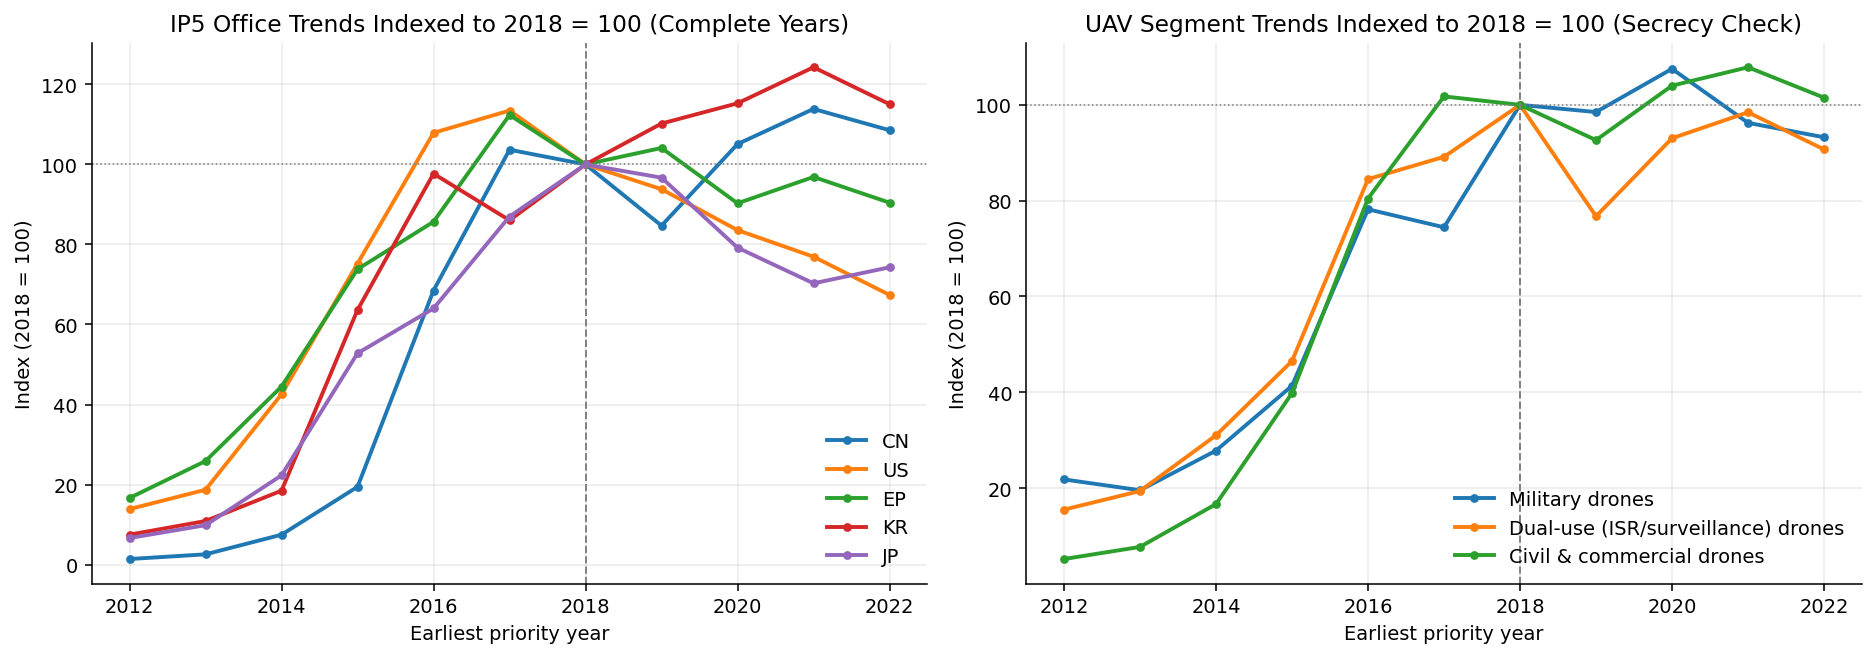

In [6]:
# 6.1 Fetch per-family filing offices & publication year for complete-window UAV families
uav_office_yr = fetch_batched(
    lambda batch: db.query(
        TLS201_APPLN.docdb_family_id.label("fid"),
        TLS201_APPLN.appln_auth.label("office"),
        func.min(TLS201_APPLN.earliest_filing_year).label("priority_year"),
        func.min(TLS201_APPLN.earliest_publn_year).label("publn_year"),
    )
    .filter(
        TLS201_APPLN.ipr_type == IPR_TYPE,
        TLS201_APPLN.docdb_family_id.in_(batch),
    )
    .group_by(TLS201_APPLN.docdb_family_id, TLS201_APPLN.appln_auth),
    uav_complete_fids,
)

# Decomposition A: By IP5 Filing Office (2016–2018 avg vs 2019–2022 avg)
off_series = (
    uav_office_yr.assign(office_grp=lambda d: d["office"].where(d["office"].isin(IP5_OFFICES + ("WO",)), "Other"))
    .groupby(["office_grp", "priority_year"])["fid"].nunique()
    .reset_index(name="n")
)
decomp_office = compute_post_peak_decomposition(off_series, category_col="office_grp", year_col="priority_year", value_col="n")
decomp_office.to_csv(OUTPUT_DIR / "post2018_decomp_by_office.csv")
print("Post-2018 Decomposition by Filing Office (2016-18 avg vs 2019-22 avg):")
display(decomp_office.round(2))

# Decomposition B: By Applicant Country
applt_ctry_yr = (
    uav_applts.merge(uav_all_prof[["fid", "year"]], on="fid", how="inner")
    .dropna(subset=["ctry"])
    .assign(ctry=lambda d: d["ctry"].astype(str).str.strip())
)
applt_ctry_yr = applt_ctry_yr[applt_ctry_yr["ctry"] != ""]
top_ctries_q4 = applt_ctry_yr.groupby("ctry")["fid"].nunique().nlargest(8).index
ctry_series = (
    applt_ctry_yr.assign(ctry_grp=lambda d: d["ctry"].where(d["ctry"].isin(top_ctries_q4), "Other"))
    .groupby(["ctry_grp", "year"])["fid"].nunique()
    .reset_index(name="n")
)
decomp_ctry = compute_post_peak_decomposition(ctry_series, category_col="ctry_grp", year_col="year", value_col="n")
decomp_ctry.to_csv(OUTPUT_DIR / "post2018_decomp_by_country.csv")
print("Post-2018 Decomposition by Applicant Country:")
display(decomp_ctry.round(2))

# Decomposition C: By UAV Use Segment (Military vs Dual-Use vs Civil)
seg_series = uav_seg_prof.groupby(["segment", "year"])["fid"].nunique().reset_index(name="n")
decomp_seg = compute_post_peak_decomposition(seg_series, category_col="segment", year_col="year", value_col="n")
decomp_seg.to_csv(OUTPUT_DIR / "post2018_decomp_by_segment.csv")
print("Post-2018 Decomposition by UAV Use Segment (Military vs Dual-Use vs Civil):")
display(decomp_seg.round(2))

# Decomposition D: By Top CPC Subclasses (Hardware vs Autonomy/Vision/UTM)
cpc_yr = (
    uav_cpc.assign(subclass=lambda d: d["cpc_class_symbol"].astype(str).str.replace(" ", "", regex=False).str[:4])
    .merge(uav_all_prof[["fid", "year"]], left_on="docdb_family_id", right_on="fid", how="inner")
)
top_cpc_q4 = cpc_yr.groupby("subclass")["fid"].nunique().nlargest(10).index
cpc_series = (
    cpc_yr[cpc_yr["subclass"].isin(top_cpc_q4)]
    .groupby(["subclass", "year"])["fid"].nunique()
    .reset_index(name="n")
)
decomp_cpc = compute_post_peak_decomposition(cpc_series, category_col="subclass", year_col="year", value_col="n")
decomp_cpc.to_csv(OUTPUT_DIR / "post2018_decomp_by_cpc_subclass.csv")
print("Post-2018 Decomposition by Top CPC Subclasses:")
display(decomp_cpc.round(2))

# Figure 3: Indexed trends (2018 = 100) by Country (CN vs US vs EP vs JP/KR) & by Segment (Military vs Dual-Use vs Civil)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8))
for ctry_code in [c for c in ("CN", "US", "EP", "KR", "JP") if c in off_series["office_grp"].unique()]:
    s = off_series[(off_series["office_grp"] == ctry_code) & (off_series["priority_year"].between(2012, LAST_COMPLETE_YEAR))].set_index("priority_year")["n"].sort_index()
    if 2018 in s.index and s.loc[2018] > 0:
        axes[0].plot(s.index, s / s.loc[2018] * 100.0, marker="o", ms=3.5, lw=2, label=ctry_code)
axes[0].axvline(2018, color="grey", ls="--", lw=1)
axes[0].axhline(100, color="grey", ls=":", lw=0.8)
axes[0].set(title="IP5 Office Trends Indexed to 2018 = 100 (Complete Years)", xlabel="Earliest priority year", ylabel="Index (2018 = 100)")
axes[0].legend(frameon=False)

for seg_k, seg_lbl in seg_label_map.items():
    s = seg_series[(seg_series["segment"] == seg_k) & (seg_series["year"].between(2012, LAST_COMPLETE_YEAR))].set_index("year")["n"].sort_index()
    if 2018 in s.index and s.loc[2018] > 0:
        axes[1].plot(s.index, s / s.loc[2018] * 100.0, marker="o", ms=3.5, lw=2, label=seg_lbl)
axes[1].axvline(2018, color="grey", ls="--", lw=1)
axes[1].axhline(100, color="grey", ls=":", lw=0.8)
axes[1].set(title="UAV Segment Trends Indexed to 2018 = 100 (Secrecy Check)", xlabel="Earliest priority year", ylabel="Index (2018 = 100)")
axes[1].legend(frameon=False)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / "fig03_post2018_diagnostic.png", bbox_inches="tight")
plt.show()
